In [1]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
%load_ext autoreload
%autoreload 2

c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [4]:
fs = slm_initialise(force=True,verbose=True)

Display Positions:
#,  Position
0,  x=1920, y=0, width=1280, height=1024
1,  x=0, y=0, width=1920, height=1200 (main)
Initializing pyglet... success
Searching for window with display_number=0... success
Creating window... [Errno 2] No such file or directory: 'C:\\Users\\QC\\Envs\\SLM_new\\Lib\\site-packages\\slmsuite\\hardware\\..\\..\\docs\\source\\static\\slmsuite-notext-16x16.png'
success
ThorCam serials:
'12975'
Looking for cameras... success
ThorCam sn '12975' initializing... success


array([[2, 2, 2, ..., 2, 2, 2],
       [2, 3, 2, ..., 2, 3, 2],
       [2, 2, 2, ..., 1, 1, 1],
       ...,
       [2, 2, 2, ..., 2, 3, 2],
       [3, 3, 2, ..., 2, 2, 2],
       [2, 1, 2, ..., 2, 3, 2]], dtype=uint16)

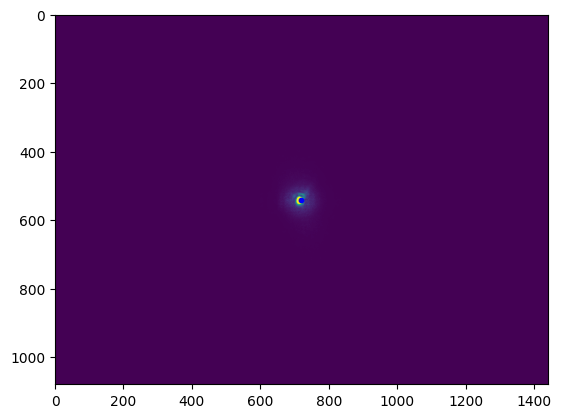

In [5]:
plot_cam(fs,phase="zero",centre=True)

In [6]:
calibrate(fs,vendor = True,refresh = False)

smooth:   0%|          | 0/16 [00:00<?, ?it/s]

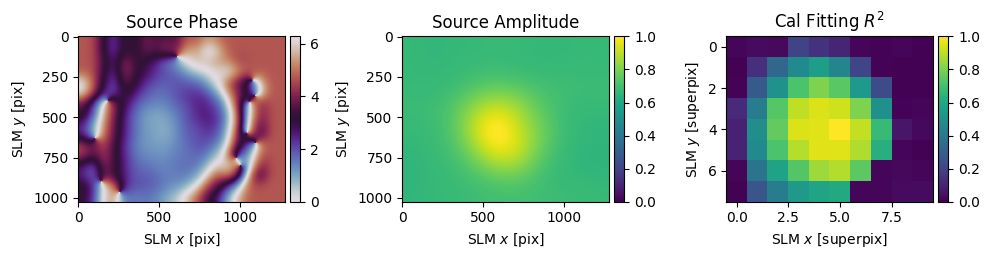

In [7]:
sp_calibrate(fs,refresh=False)

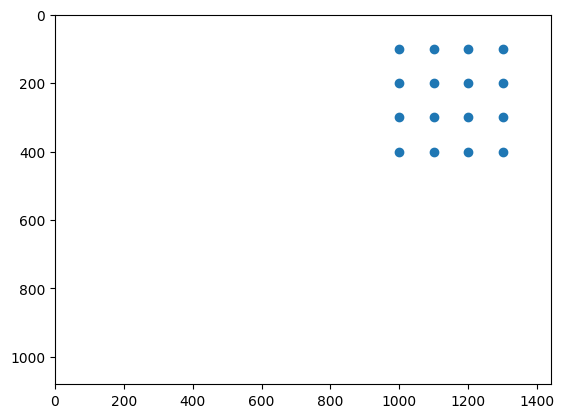

c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_hologram.py:377: UserWarning:

Hologram target shape (1024, 1280) is not a power of 2; consider using .get_padded_shape() to pad to powers of 2 and speed up FFT computation. While some FFT solvers support other prime powers (3, 5, 7, ...), literature suggests that GPU support is best for powers of 2.



  0%|          | 0/30 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing sh

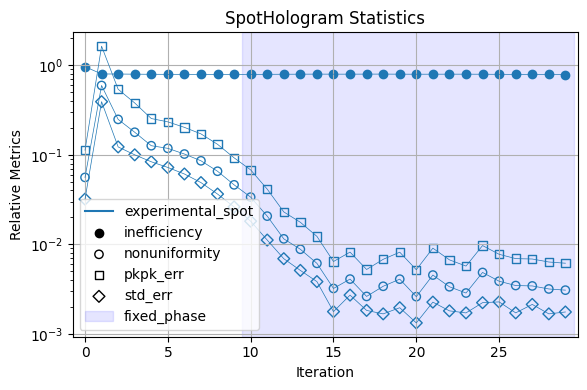

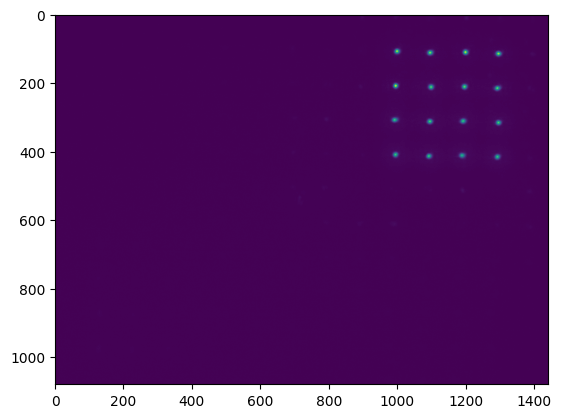

In [ ]:
holo = create_tweezers(fs)

array([[4, 3, 4, ..., 2, 2, 3],
       [5, 4, 3, ..., 2, 2, 2],
       [4, 5, 4, ..., 1, 2, 2],
       ...,
       [3, 2, 3, ..., 1, 2, 3],
       [3, 3, 3, ..., 2, 2, 2],
       [3, 4, 4, ..., 2, 3, 2]], dtype=uint16)

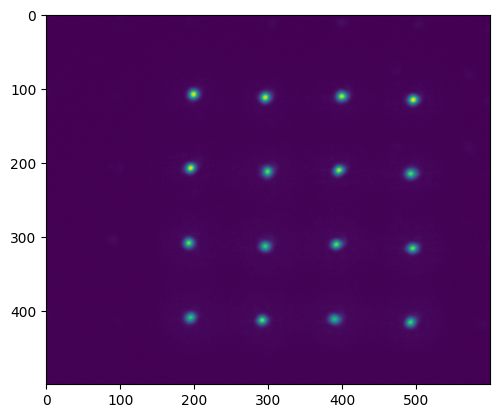

In [13]:
plot_cam(fs,limits=(slice(0, 500), slice(800, 1400)))

writing phase


array([[2, 3, 1, ..., 2, 2, 2],
       [2, 3, 2, ..., 3, 2, 2],
       [2, 1, 2, ..., 1, 2, 3],
       ...,
       [2, 1, 2, ..., 2, 2, 3],
       [3, 3, 4, ..., 2, 2, 2],
       [2, 2, 2, ..., 2, 2, 1]], dtype=uint16)

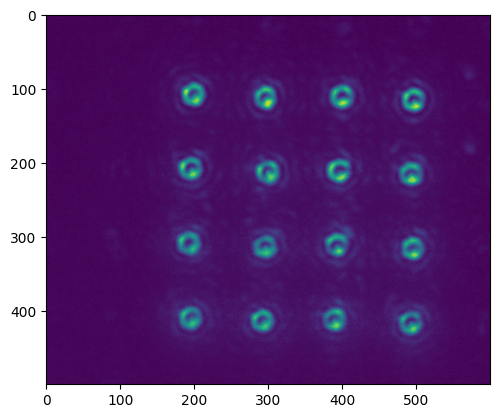

In [14]:
plot_cam(fs,phase = bottle_beam_phase(fs)+holo.phase,limits=(slice(0, 500), slice(800, 1400)))

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


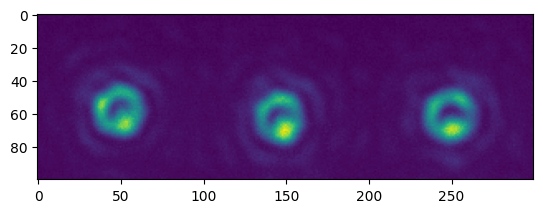

In [15]:
img = plot_cam(fs,phase = bottle_beam_phase(fs)+holo.phase,limits=(slice(50, 150), slice(950, 1250)))

## Combining g and bb

optimised params are [2.65128552e+04 2.65082789e+04 9.26105422e+00 9.23567108e+00
 5.75361745e+01 4.86075289e+01 4.00557829e+00]


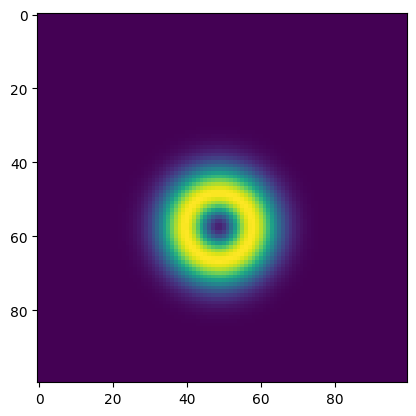

In [20]:
plot_fit(target = img[:,0:100],trap = "bb")

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning:

The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.



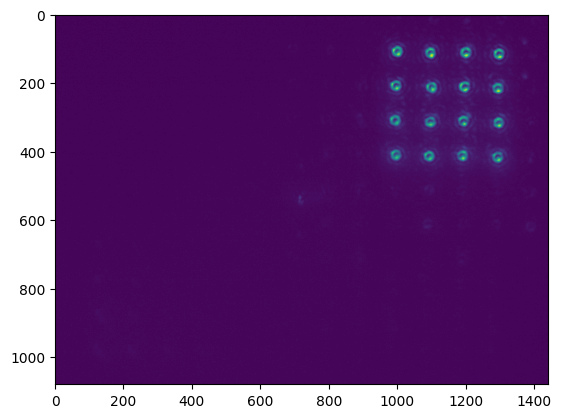

In [21]:
img = plot_cam(fs,phase = bottle_beam_phase(fs)+holo.phase)

In [120]:
convert_vector((0,0),hardware=fs,from_units="ij",to_units="knm")

array([[734.6943901 ],
       [406.69347811]])

In [127]:
(*convert_vector((600,600),hardware=fs,from_units="knm",to_units="ij"))

SyntaxError: cannot use starred expression here (545687825.py, line 1)

In [ ]:
fs.ijcam_to_knmslm((0,0))

AttributeError: 'FourierSLM' object has no attribute 'ijcam_to_knmslm'

In [9]:
scaling = 1
target = np.array([[bb(x,y,2.65128552e+04, 2.65128552e+04, 9.26105422*scaling, 9.23567108*scaling,1180,230) for x in range(fs.cam.shape[1]*scaling)] for y in range(fs.cam.shape[0]*scaling)])

In [29]:
hologram = FeedbackHologram(shape = (2048*2,2048*2),target_ij=target, cameraslm=fs)

In [11]:
fs.slm.shape

(1024, 1280)

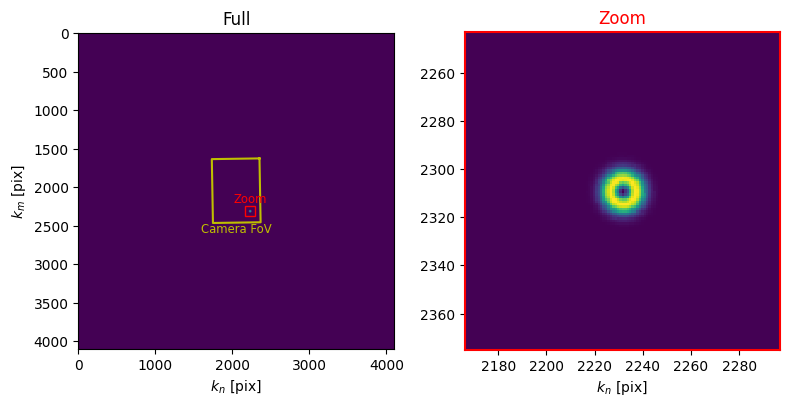

In [30]:
limits = hologram.plot_farfield(hologram.target)

In [31]:
hologram.optimize(
    method="WGS-Leonardo",
    maxiter=30,
    feedback='computational',
    stat_groups=['computational'],
    plot=True
)

  0%|          | 0/30 [00:00<?, ?it/s]

c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_hologram.py:1794: RuntimeWarning: divide by zero encountered in divide
  xp.divide(feedback_corrected, xp.array(target_amp, copy=(False if np.__version__[0] == '1' else None)), out=feedback_corrected)
c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_hologram.py:1794: RuntimeWarning: overflow encountered in divide
  xp.divide(feedback_corrected, xp.array(target_amp, copy=(False if np.__version__[0] == '1' else None)), out=feedback_corrected)


<Axes: title={'center': 'FeedbackHologram Statistics'}, xlabel='Iteration', ylabel='Relative Metrics'>

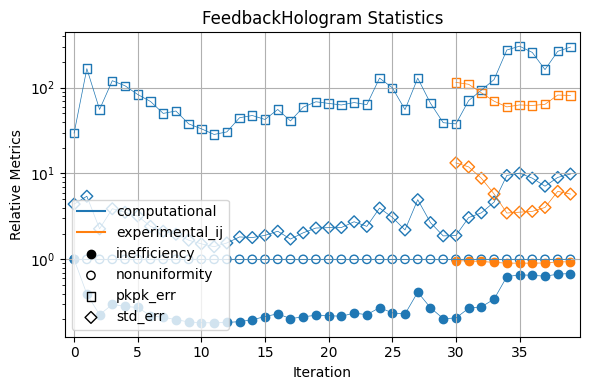

In [35]:
hologram.plot_stats()

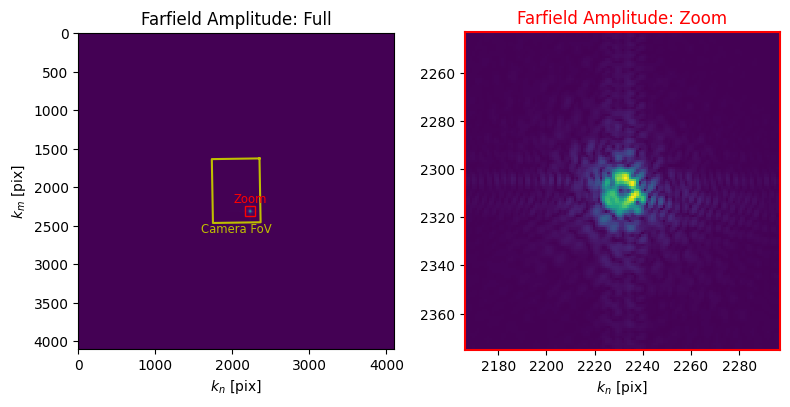

[array([2166, 2297]), array([2243, 2375])]

In [33]:
hologram.plot_farfield()

In [37]:
hologram.optimize(
    method="WGS-Leonardo",
    maxiter=30,
    feedback='experimental',
    stat_groups=['computational', 'experimental'],
    blur_ij=1
)

  0%|          | 0/30 [00:00<?, ?it/s]

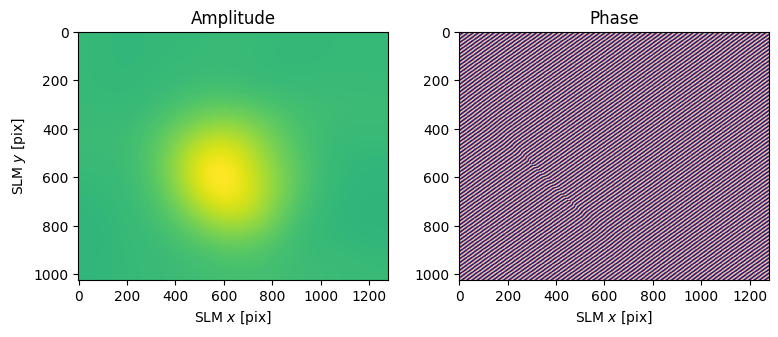

In [17]:
hologram.plot_nearfield()

In [38]:
hologram.get_phase()

array([[1.8198619, 2.1086264, 2.3973887, ..., 1.860147 , 2.149421 ,
        2.438695 ],
       [2.2212734, 2.5100446, 2.7988133, ..., 2.2548316, 2.5441108,
        2.8333898],
       [2.6226697, 2.9114473, 3.2002225, ..., 2.6495075, 2.938792 ,
        3.2280762],
       ...,
       [3.8582075, 4.1478634, 4.437515 , ..., 4.455541 , 4.7438745,
        5.032208 ],
       [4.255105 , 4.5447674, 4.8344254, ..., 4.859946 , 5.148267 ,
        5.4365883],
       [4.6519976, 4.9416666, 5.231331 , ..., 5.264428 , 5.5527363,
        5.8410463]], dtype=float32)

writing phase


array([[2, 2, 2, ..., 2, 2, 2],
       [2, 3, 1, ..., 2, 2, 1],
       [2, 2, 2, ..., 2, 1, 1],
       ...,
       [1, 2, 2, ..., 2, 3, 2],
       [2, 3, 3, ..., 2, 2, 1],
       [3, 2, 2, ..., 3, 2, 2]], dtype=uint16)

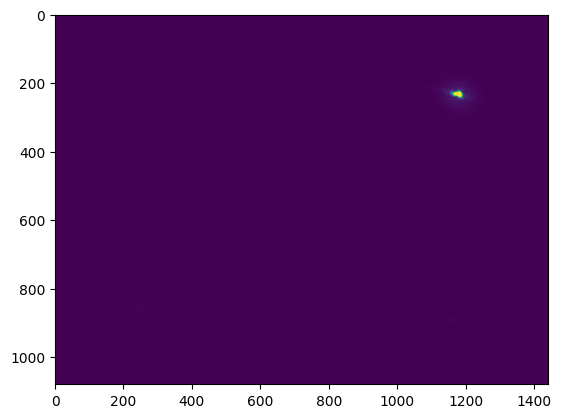

In [40]:
plot_cam(fs,phase=hologram.get_phase())

In [45]:
limits

[array([761, 808]), array([592, 627])]

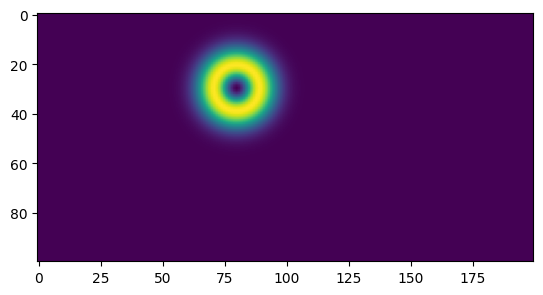

In [52]:
plt.imshow(target[200:300,1100:1300])

In [ ]:
""